In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, ConfusionMatrixDisplay

print('Semua library berhasil diimpor!')

Semua library berhasil diimpor!


In [ ]:
uploaded = files.upload()

nama_file = next(iter(uploaded))
dataset = pd.read_csv('student_data.csv')

print("Dataset berhasil diimpor!")
print("Ukuran dataset:", dataset.shape)

dataset.head()

Saving student_data.csv to student_data (1).csv
Dataset berhasil diimpor!
Ukuran dataset: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Menampilan inforamsi dataset


In [ ]:
print("Informasi dataset:")
dataset.info()

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    obj

Menampilkan jumlah data kosong

In [ ]:
print('\nJumlah data kosong:')
print(dataset.isnull().sum())


Jumlah data kosong:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


Menampilkan nama kolom

In [ ]:
print("\nNama-nama kolom:")
print(dataset.columns.tolist())


Nama-nama kolom:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


Menampilkan statistik deskriptif


In [ ]:
print("\nStatistik deskriptif:")
print(dataset.describe())


Statistik deskriptif:
              age        Medu        Fedu  traveltime   studytime    failures  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean    16.696203    2.749367    2.521519    1.448101    2.035443    0.334177   
std      1.276043    1.094735    1.088201    0.697505    0.839240    0.743651   
min     15.000000    0.000000    0.000000    1.000000    1.000000    0.000000   
25%     16.000000    2.000000    2.000000    1.000000    1.000000    0.000000   
50%     17.000000    3.000000    2.000000    1.000000    2.000000    0.000000   
75%     18.000000    4.000000    3.000000    2.000000    2.000000    0.000000   
max     22.000000    4.000000    4.000000    4.000000    4.000000    3.000000   

           famrel    freetime       goout        Dalc        Walc      health  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean     3.944304    3.235443    3.108861    1.481013    2.291139    3.554430   
std 

1.   Membuat kolom status kelulusan berdasarkan nilai akhirG3
2.   Menampilkan jumlah siswa berdasarkan status

3. Menampilkan contoh data

In [14]:
dataset['Status'] = np.where(dataset['G3'] >= 10,'Lulus','Tidak Lulus')
print("Jumlah siswa berdasarkan status kelulusan:")
print(dataset['Status'].value_counts())
display(dataset[['G1', 'G2', 'G3', 'Status']].head(10))

Jumlah siswa berdasarkan status kelulusan:
Status
Lulus          265
Tidak Lulus    130
Name: count, dtype: int64


,G1,G2,G3,Status
0,5,6,6,Tidak Lulus
1,5,5,6,Tidak Lulus
2,7,8,10,Lulus
3,15,14,15,Lulus
4,6,10,10,Lulus
5,15,15,15,Lulus
6,12,12,11,Lulus
7,6,5,6,Tidak Lulus
8,16,18,19,Lulus
9,14,15,15,Lulus


* Menentukan variabel fitur (x)
* Kolom G3 tidak digunakan sebagai fitur karena menjadi dasar target klasifikasi
* Menentukan variable target (y)




In [15]:
x = dataset.drop(columns=['G3','Status'])
y = dataset['Status']

print("Variabel fitur (x):")
print(x.head())

print("\nVariabel target (y):")
print(y.head())

print("\nJumlah fitur:", x.shape[1])
print("Jumlah target:", y.shape[0])

Variabel fitur (x):
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  romantic famrel  freetime  goout  Dalc Walc health absences  G1  G2  
0       no      4         3      4     1    1      3        6   5   6  
1       no      5         3      3     1    1      3        4   5   5  
2       no      4         3      2     2    3      3       10   7   8  
3      yes      3         2      2     1    1      5        2  15  14  
4       no      4         3      2     1    2      5        4   6  10  

[5 rows x 32 columns]

Variabel target (y):
0    Tidak Lulus

In [16]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=0, stratify=y)

print("Jumlah data latih:", len(x_train))
print("Jumlah data uji:", len(x_test))

print("\nUkuran x_train:", x_train.shape)
print("Ukuran x_test:", x_test.shape)

print("\nUkuran y_train:", y_train.shape)
print("Ukuran y_test:", y_test.shape)

Jumlah data latih: 296
Jumlah data uji: 99

Ukuran x_train: (296, 32)
Ukuran x_test: (99, 32)

Ukuran y_train: (296,)
Ukuran y_test: (99,)


Memisahkan kolom numerik dan kategorikal

In [17]:
kolom_numerik = x.select_dtypes(include=['int64', 'float64']).columns.tolist()
kolom_kategorikal = x.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print("Kolom numerik:")
print(kolom_numerik)

print("\nKolom kategorikal:")
print(kolom_kategorikal)

Kolom numerik:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Kolom kategorikal:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


Preprocessing data

In [18]:
preprocessor = ColumnTransformer(transformers=[('numerik', StandardScaler(), kolom_numerik), ('kategorikal', OneHotEncoder(handle_unknown='ignore', sparse_output=False), kolom_kategorikal)])

print("\nPreprocessing berhasil disiapkan!")


Preprocessing berhasil disiapkan!


Membuat model Gaussian Naive Bayes

In [25]:
model = Pipeline(
    steps=[
        ('preprocessing', preprocessor),
        ('classifier', GaussianNB())
    ]
)

Melatih model menggunakan data latih

In [26]:
model.fit(x_train, y_train)
print("Model Gaussian Naive Bayes berhasil dilatih!")

Model Gaussian Naive Bayes berhasil dilatih!


Melakukan prediksi data uji

In [28]:
y_pred = model.predict(x_test)

hasil_prediksi = pd.DataFrame({
    'Status Aktual': y_test,
    'Status Prediksi': y_pred
})

print("Hasil prediksi Naive Bayes:")
display(hasil_prediksi.head(10))

Hasil prediksi Naive Bayes:


,Status Aktual,Status Prediksi
135,Tidak Lulus,Tidak Lulus
69,Lulus,Lulus
42,Lulus,Lulus
210,Tidak Lulus,Tidak Lulus
59,Lulus,Lulus
104,Lulus,Lulus
251,Lulus,Tidak Lulus
268,Lulus,Lulus
117,Lulus,Lulus
50,Lulus,Lulus


Menghitung akurasi

In [30]:
akurasi = accuracy_score(y_test, y_pred)

print("Akurasi model Naive Bayes: {:.2f}%".format(akurasi * 100))

Akurasi model Naive Bayes: 82.83%


Membuat confusion matrix

In [33]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['Tidak Lulus', 'Lulus']
)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[25  8]
 [ 9 57]]


Menampilkan confusion matirx dalan bentuk grafik

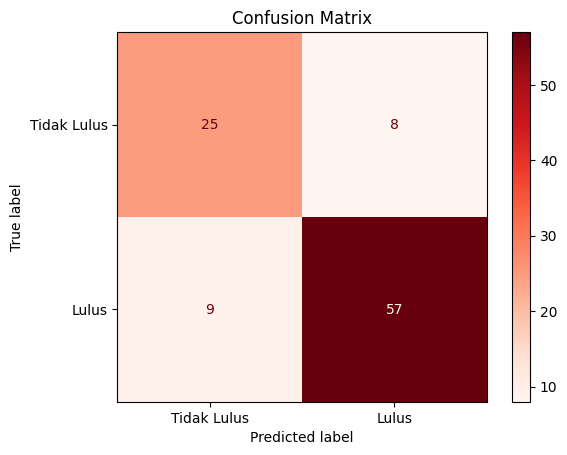

In [38]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Tidak Lulus', 'Lulus']
)
disp.plot(cmap='Reds')
plt.title('Confusion Matrix')
plt.show()